# MSH 3-T-junction array: tensor-network LDOS, Z/X gates, fusion readout and δn(x, t)

The tensor-network calculation for the 3-T-junction array. Every reported quantity comes from MPO/MPS methods: DMRG for the subgap
states and the Majoranas, TDVP for the gates and the fusion readout. Dense matrices appear only in the check that the MPO equals the
lattice Hamiltonian (section 4). The exact-diagonalization reference is `tjunctions_python_ed.ipynb` (kwant); it reads the `tb_reference/`
matrices written in section 4 to check that both codes build the same Hamiltonian, and `tjunctions_compare.ipynb` compares the results
of the two notebooks.

**Model.** Chain sites only: horizontal chain $y = 0$, $x = -48\dots47$, T-junctions at $x_c = -32, 0, 32$, vertical legs
$y = 1\dots16$ (144 sites). Nambu basis $(c_\uparrow, c_\downarrow, c^\dagger_\uparrow, c^\dagger_\downarrow)$,
$H_{\rm BdG} = [[H_0, \Delta i\sigma_y], [(\Delta i\sigma_y)^\dagger, -H_0^*]]$, $H_0 = -\mu + J\,\mathbf S\cdot\boldsymbol\sigma$ on sites and
$c^\dagger_{r+\hat d}\,(-t + i\alpha(d_x\sigma_y - d_y\sigma_x))\,c_r$ on bonds; $t=1$, $\mu=-7$, $\alpha=0.9$, $\Delta=2.4$, $J=5.8$.
Texture $\theta = (-1)^{x+y}\tfrac{\pi}{2}f$, $\phi = \theta_{\rm arm} + \pi/2$: $f = 0$ topological ($\mathbf S\parallel\hat z$), $f = 1$ trivial
(in-plane AFM). Initial setup: junctions 1 and 3 have topological horizontal legs, the rest is trivial → four MZMs.

**Tensor-network parts.**
* $H$ is an MPO (TensorBinding.jl) on `[nambu; spin; cell; pos₁…pos₄; arm]`; $H(t)$ rebuilds only the exchange of the moving cells.
* LDOS and MZMs: penalized DMRG on $K = H^2 + \eta^2$, Rayleigh–Ritz in $H$, inverse-iteration refinement, localization with the position MPO.
* Gates and fusion: the two zero-mode fermions $\psi_A$, $\psi_B$ are evolved as MPS with 2-site TDVP. The braid matrix, logical gate, leakage,
  $\Delta Q$ and $\delta n(x, t)$ come from MPS overlaps and local contractions.

**Contents**
1. Hamiltonian: MPO and dense lattice reference
2. Protocols for $\sqrt{Z}$ and $\sqrt{X}$ gates and the partial fusion
3. MPS functions: 3a. time evolution and readout, 3b. zero modes from DMRG
4. Check: MPO vs dense lattice matrix; export of `tb_reference/`
5. Subgap LDOS and MZMs from DMRG
6. Gates followed by partial fusion with TDVP (Z, X with `rot_Tx = 400`, fusion only)
7. ΔQ during the fusion and the bond dimension
8. Summary of the results
9. Cost of the tensor-network route

**Runtime.** With the TDVP results cached (`msh_tjunctions_tdvp_{Z,X,F}.jls`), about 10 minutes (DMRG). The first TDVP run takes about 2.5 hours
with six Julia threads (start Jupyter with `JULIA_NUM_THREADS=6`; one thread per mode and run) and logs its progress to `tdvp_progress.log`
and `tdvp_status.txt` (section 6).

**Outputs:** `msh_array_ldos_tn.csv`, `msh_gate_density_tdvp_{Z,X}.csv`, `msh_gate_dQ_tdvp_{Z,X}.csv`, `msh_tjunctions_tn_gates.csv`,
`msh_tjunctions_tn_timing.csv`, `tb_reference/`, figures `nb_tn_ldos.png`, `nb_tdvp_density_{Z,X}.png`, `nb_tdvp_dQ.png`.

In [1]:
using LinearAlgebra, Printf, Random, Logging, Serialization
using ITensors, ITensorMPS, Plots
using TensorBinding
const TB = TensorBinding

const ROOT = pwd()          # CSVs, caches, logs and figures are read from / written to the notebook's folder
const RUN_TDVP = false      # true: rerun the TDVP of section 6 even if its cache files exist (about 2.5 h with 6 threads)
const σ0 = ComplexF64[1 0; 0 1];  const σx = ComplexF64[0 1; 1 0]
const σy = ComplexF64[0 -im; im 0]; const σz = ComplexF64[1 0; 0 -1]
# KrylovKit warns at every non-converged local solve in DMRG on K and in linsolve (harmless); show errors only
quiet(f) = with_logger(f, ConsoleLogger(stderr, Logging.Error))
println("Julia threads: ", Threads.nthreads())

Julia threads: 6


## 1. Hamiltonian: MPO and dense reference

* `diag_mpo_exact`: exact diagonal MPO (TT-SVD) for the site-dependent exchange field.
* `msh_tjunction_array(a, f)`: BdG MPO. Intra-arm hopping with `shift_pair_mpos(cyclic=false)`, junction bonds via the site-0
  projector, inter-cell bonds via the site-$(N-1)$ projector. Each cell is a lattice T: arm 1 runs right from the junction site,
  arm 2 left from $x_c - 1$, arm 3 up from $y = 1$.
* `array_reference(a, f)`: independent dense matrix built only from site coordinates (all pairs one lattice spacing apart).
* `array_exchange_mpo`: exchange of selected cells only, so $H(t)$ = fixed part + moving exchange.

`f(c, s, n)` is the rotation fraction on cell `c`, arm `s` (1 right, 2 left, 3 up), site `n` along the arm.

In [2]:
# exact diagonal MPO diag(v) on the position qubits (pos[1] = most significant bit)
function diag_mpo_exact(v::AbstractVector, pos; cutoff=1e-14)
    L = length(pos)
    A = permutedims(reshape(ComplexF64.(v), ntuple(_ -> 2, L)), L:-1:1)
    ψ = MPS(A, pos; cutoff=cutoff)
    W = MPO(pos, "Id")
    for k in 1:L
        s = pos[k]
        δ = ITensor(ComplexF64, s, s', dag(s''))
        for j in 1:2; δ[s => j, s' => j, s'' => j] = 1; end
        W[k] = replaceprime(ψ[k] * δ, 2 => 0; tags=tags(s))
    end
    return W
end

# dense matrix of an MPO (big-endian over `sites`), for the check against the lattice matrix
dense(mpo, sites) = (T = ITensors.@disable_warn_order prod(mpo); D = prod(dim.(sites));
                     reshape(Array(T, reverse(prime.(sites))..., reverse(sites)...), D, D))

# hopping c†_{r+d} h c_r along the unit bond d
hop_matrix(t, α, d) = -t * σ0 + im * α * (d[1] * σy - d[2] * σx)

Base.@kwdef struct TArray
    L::Int = 4          # 2^L = 16 sites per arm
    ncell::Int = 3
end
Ncell(a::TArray) = 2^a.L
const ARM_ANG = (0.0, π, π/2)                         # right, left, up
const ARM_ORIG = ((0.0, 0.0), (-1.0, 0.0), (0.0, 1.0))
center_x(a::TArray, c) = (c - (a.ncell + 1) / 2) * 2Ncell(a)
array_pos(a::TArray, c, s, n) = (center_x(a, c), 0.0) .+ ARM_ORIG[s] .+ n .* (cos(ARM_ANG[s]), sin(ARM_ANG[s]))
array_spin(a::TArray, f) = (c, s, n) -> begin
    x, y = round.(Int, array_pos(a, c, s, n))
    θ = (-1)^(x + y) * (π/2) * f(c, s, n); φ = ARM_ANG[s] + π/2
    (cos(φ) * sin(θ), sin(φ) * sin(θ), cos(θ))
end

# `sites` reuses existing site indices, so MPS built on one Hamiltonian work with another
function msh_tjunction_array(a::TArray, f; t=1.0, μ=-7.0, α=0.9, Δ=2.4, J=5.8, cutoff=1e-13, sites=nothing)
    L, N, nc = a.L, Ncell(a), a.ncell
    ns, ss, cl, pos, arm = isnothing(sites) ?
        (TB.nambu_index(), TB.spin_index(), Index(nc, "Cell"), siteinds("Qubit", L), TB.tjunction_index()) :
        (sites[1], sites[2], sites[3], sites[4:end-1], sites[end])
    term(Mpos, σmat, Bcell, Barm) =
        TB.prepend_op(TB.prepend_op(TB.postpend_op(Mpos, arm, Barm), cl, Bcell), ss, σmat)
    P(d, i) = (m = zeros(d, d); m[i, i] = 1.0; m)
    E(d, i, j) = (m = zeros(d, d); m[i, j] = 1.0; m)         # |i⟩⟨j|
    Ic, I3, Id = Matrix(1.0I, nc, nc), Matrix(1.0I, 3, 3), MPO(pos, "Id")
    Ku, Kd = TB.shift_pair_mpos(pos, 1; cyclic=false)

    terms = MPO[term(-μ * Id, σ0, Ic, I3)]
    for s in 1:3                                              # intra-arm hopping
        h = hop_matrix(t, α, (cos(ARM_ANG[s]), sin(ARM_ANG[s])))
        push!(terms, term(Ku, h, Ic, P(3, s)), term(Kd, Matrix(h'), Ic, P(3, s)))
    end
    P0 = TB._site_projector_mpo(L, pos, 0)                     # junction bonds
    for (a_, b_, d) in ((2, 1, (1.0, 0.0)), (1, 2, (-1.0, 0.0)), (3, 1, (0.0, -1.0)), (1, 3, (0.0, 1.0)))
        push!(terms, term(P0, hop_matrix(t, α, d), Ic, E(3, b_, a_)))
    end
    Pend = TB._site_projector_mpo(L, pos, N - 1)               # inter-cell: right end of c → left end of c+1
    h = hop_matrix(t, α, (1.0, 0.0))
    for c in 1:nc-1
        push!(terms, term(Pend, h, E(nc, c + 1, c), E(3, 2, 1)),
                     term(Pend, Matrix(h'), E(nc, c, c + 1), E(3, 1, 2)))
    end
    S = array_spin(a, f)                                       # exchange J S·σ
    for c in 1:nc, s in 1:3, (k, σ) in enumerate((σx, σy, σz))
        v = [J * S(c, s, n)[k] for n in 0:N-1]
        maximum(abs, v) > 1e-14 && push!(terms, term(diag_mpo_exact(v, pos), σ, P(nc, c), P(3, s)))
    end
    H0 = +(terms...; cutoff)

    Hp  = term(Δ * Id, ComplexF64[0 1; -1 0], Ic, I3)
    Hpd = swapprime(dag(Hp), 0, 1)
    HB  = +(TB.prepend_nambu(H0, ns, :Pp), TB.prepend_nambu(-1.0 * dag(H0), ns, :Ph),
            TB.prepend_nambu(Hp, ns, :tp), TB.prepend_nambu(Hpd, ns, :tm); cutoff)
    return HB, [ns; ss; cl; pos; arm]
end

"Independent dense BdG matrix from site coordinates only (same basis as dense(HB, sites))."
function array_reference(a::TArray, f; t=1.0, μ=-7.0, α=0.9, Δ=2.4, J=5.8)
    N, nc = Ncell(a), a.ncell; S = array_spin(a, f); M = 3N * nc
    idx(c, s, n) = (c - 1) * 3N + 3n + s                       # cell ⊗ pos ⊗ arm, arm fastest
    allsites = [(c, s, n, array_pos(a, c, s, n)) for c in 1:nc for s in 1:3 for n in 0:N-1]
    H0 = zeros(ComplexF64, 2M, 2M)
    blk(i) = [i, M + i]
    for (c, s, n, r) in allsites
        i = idx(c, s, n); Sn = S(c, s, n)
        H0[blk(i), blk(i)] .+= -μ * σ0 + J * (Sn[1] * σx + Sn[2] * σy + Sn[3] * σz)
        for (c2, s2, n2, r2) in allsites
            d = r2 .- r
            abs(hypot(d...) - 1) < 1e-9 && (H0[blk(idx(c2, s2, n2)), blk(i)] .+= hop_matrix(t, α, d))
        end
    end
    D = kron(Δ * ComplexF64[0 1; -1 0], Matrix(1.0I, M, M))
    return [H0 D; D' -conj(H0)]
end

"Exchange J S·σ (particle σ, hole −σ*) of the given cells only, as a BdG MPO on `sites`."
function array_exchange_mpo(a::TArray, sites, f, cells; J=5.8, cutoff=1e-14)
    ns, ss, cl, pos, arm = sites[1], sites[2], sites[3], sites[4:end-1], sites[end]
    S = array_spin(a, f); N = Ncell(a); H = nothing
    for c in cells, s in 1:3, (k, σ) in enumerate((σx, σy, σz))
        v = [J * S(c, s, n)[k] for n in 0:N-1]
        maximum(abs, v) > 1e-14 || continue
        Pc = zeros(a.ncell, a.ncell); Pc[c, c] = 1.0
        Pa = zeros(3, 3); Pa[s, s] = 1.0
        D = TB.prepend_op(TB.postpend_op(diag_mpo_exact(v, pos), arm, Pa), cl, Pc)
        m = +(TB.prepend_nambu(TB.prepend_op(D, ss, σ), ns, :Pp),
              TB.prepend_nambu(TB.prepend_op(D, ss, -conj(σ)), ns, :Ph); cutoff)
        H = isnothing(H) ? m : +(H, m; cutoff)
    end
    return H
end

"Diagonal position operator r·û (û at angle β) on [nambu; spin; cell; pos; arm]."
function array_position_mpo(a::TArray, sites; β=0.05)
    ns, ss, cl, pos, arm = sites[1], sites[2], sites[3], sites[4:end-1], sites[end]
    u = (cos(β), sin(β)); X = nothing
    for c in 1:a.ncell, s in 1:3
        Pc = zeros(a.ncell, a.ncell); Pc[c, c] = 1.0
        Pa = zeros(3, 3); Pa[s, s] = 1.0
        v = [sum(array_pos(a, c, s, n) .* u) for n in 0:Ncell(a)-1]
        m = TB.prepend_op(TB.postpend_op(diag_mpo_exact(v, pos), arm, Pa), cl, Pc)
        X = isnothing(X) ? m : +(X, m; cutoff=1e-14)
    end
    return TB.prepend_op(TB.prepend_op(X, ss, σ0), ns, σ0)
end

site_list(a) = [(c, s, n) for c in 1:a.ncell for n in 0:Ncell(a)-1 for s in 1:3]      # all sites (order of the LDOS CSV)

site_list (generic function with 1 method)

## 2. Protocols for $\sqrt{Z}$ and $\sqrt{X}$ gates:

`smoothstep(τ) = sin²(πτ/2)` on [0, 1]; each site's $f$ ramps with a site-dependent delay `step_T · d`, τ = t / rot_T.
The ramps are written for legs of $L_1 = L_2 = 14$ sites and mapped onto the 16-site legs of the array.
* **$\sqrt{Z}$: exchange_12** (cell 1, `rot_Tz = 200`, `step_Tz = 0.1`) exchanges γ₁ and γ₂ around junction 1's vertical leg; Z = exchange_12 × 2.
  Arm 1 $n \leftrightarrow i = L_1 + 1 + n$; arm 2 $n \leftrightarrow i = \max(L_1 - n, 0)$; arm 3 $n \leftrightarrow k = \min(n, L_2)$.
* **$\sqrt{X}$: exchange_23** (cell 2, `rot_Tx = 100` or 400) exchanges γ₂ and γ₃ through the trivial junction 2; X = exchange_23 × 2.
  Right arm $i = 3L_1 + 3 + n$; the left arm's 16 sites are mapped linearly onto $i = 3L_1 + 2 \dots 2L_1 + 3$.
* **Partial fusion** of pair A (cell 1, `rot_T0 = 100`, `step_T0 = 0.2`, `Lp = 1`): both halves turn trivial from
  the outer ends inward, leaving $2L_p + 1 = 3$ topological sites around the junction.

In [3]:
smoothstep(τ) = τ <= 0 ? 0.0 : τ >= 1 ? 1.0 : sin(π * τ / 2)^2
const f0 = (c, s, n) -> (c == 2 || s == 3) ? 1.0 : 0.0     # initial setup

Base.@kwdef struct Exchange12
    L1::Int = 14; L2::Int = 14; rot_T::Float64 = 200.0; step_T::Float64 = 0.1
end
duration(p::Exchange12) = (p.step_T * (4p.L1 + 2p.L2 + 8) + 1) * p.rot_T      # duration of one exchange
function f_horizontal(p::Exchange12, i, t)
    τ, s, L1, L2 = t / p.rot_T, p.step_T, p.L1, p.L2; ss = smoothstep
    0 <= i <= L1           && return ss(τ - s * (i + L1 + L2 + 2)) - ss(τ - s * (L1 - i + 3L1 + 2L2 + 8))
    i == L1 + 1            && return 0.0
    L1 + 2 <= i <= 2L1 + 2 && return ss(τ - s * (2L1 + 2 - i)) - ss(τ - s * (i + L1 + L2 + 2))
    return 1.0
end
f_vertical(p::Exchange12, k, t) = (τ = t / p.rot_T; s = p.step_T; ss = smoothstep;
                                   1 - ss(τ - s * (k + p.L1 + 2)) + ss(τ - s * (p.L2 - k + 3p.L1 + p.L2 + 5)))
f_braid(p::Exchange12, t) = (s, n) -> s == 1 ? f_horizontal(p, p.L1 + 1 + n, t) :
                                      s == 2 ? f_horizontal(p, max(p.L1 - n, 0), t) :
                                               f_vertical(p, min(n, p.L2), t)
f_array_braid(a::TArray, p::Exchange12, f0, t) = (c, s, n) -> c == 1 ? f_braid(p, t)(s, n) : f0(c, s, n)

Base.@kwdef struct Exchange23
    L1::Int = 14; L2::Int = 14; rot_T::Float64 = 100.0; step_T::Float64 = 0.1
end
duration(p::Exchange23) = (p.step_T * (p.L1 + 3p.L2 + 2p.L1 + 3) + 1) * p.rot_T
function f_h23(p::Exchange23, i, t)
    τ, s, L1, L2 = t / p.rot_T, p.step_T, p.L1, p.L2; ss = smoothstep
    2L1 + 3 <= i <= 3L1 + 3 && return 1 - ss(τ - s * (i - 2L1 - 3)) + ss(τ - s * (4L1 + 4 - i + L2 + L1 + 2))
    3L1 + 4 <= i <= 4L1 + 4 && return 1 - ss(τ - s * (4L1 + 4 - i + L2 + L1 + 1)) + ss(τ - s * (i - 3L1 - 4 + 3L2 + 2L1 + 3))
    error("i = $i outside junction 2's segment")
end
f_v23(p::Exchange23, k, t) = (τ = t / p.rot_T; s = p.step_T; ss = smoothstep;
                              1 - ss(τ - s * (k + p.L1 + 2)) + ss(τ - s * (p.L2 - k + 3p.L1 + p.L2 + 5)))
f_cell2_23(p::Exchange23, t) = (s, n) -> s == 1 ? f_h23(p, 3p.L1 + 3 + n, t) :
                                         s == 2 ? f_h23(p, (3p.L1 + 2) - (p.L1 - 1) * n / (p.L1 + 1), t) :
                                                  f_v23(p, min(n, p.L2), t)
f_array_23(p::Exchange23, f0, t) = (c, s, n) -> c == 2 ? f_cell2_23(p, t)(s, n) : f0(c, s, n)

Base.@kwdef struct Fusion
    L1::Int = 14; Lp::Int = 1; rot_T::Float64 = 100.0; step_T::Float64 = 0.2
end
duration(q::Fusion) = ((q.L1 - q.Lp + 1) * q.step_T + 1) * q.rot_T              # duration of the fusion ramp
function f_fuse(q::Fusion, f0, t)
    τ = t / q.rot_T; N = 16
    return (c, s, n) -> begin
        c == 1 || return f0(c, s, n)
        s == 3 && return 1.0
        s == 2 && n < q.Lp && return 0.0
        s == 1 && n <= q.Lp && return 0.0
        return smoothstep(τ - q.step_T * (N - 1 - n))       # outer end (n = 15) first
    end
end

f_fuse (generic function with 1 method)

## 3. MPS functions

**3a** evolves the zero-mode fermions with TDVP and reads out the gate and the charge from MPS overlaps and local contractions.
**3b** finds and localizes the zero modes with DMRG. Only the 4×4 braid matrix and the 4×4 Fock-space logical gate are dense.

### 3a. Time evolution and readout

**Evolution.** `MovingArrayH`: $H(t)$ = fixed part (μ, hopping, Rashba, pairing, exchange of the cells that do not move) + exchange of
the moving cells, as an MPO `B(t)`. `evolve_mode_tdvp` runs 2-site TDVP (`TB.evolve_with_tdvp_timedep`, $H$ frozen at the midpoint of each
step, $dt = 0.1$, `reverse_step = true`, `maxdim = 64`) from one snapshot time to the next and records the readout at every snapshot.

**Gate.** The evolution is quadratic, so $\hat U\hat\gamma_j\hat U^\dagger = \sum_i\hat\gamma_i M_{ij}$ with $M_{ij} = \langle\gamma_i(0)|\gamma_j(T)\rangle$.
Only $\psi_A = (\gamma_1 + i\gamma_2)/\sqrt2$ and $\psi_B = (\gamma_3 + i\gamma_4)/\sqrt2$ (positive-energy members) are evolved;
$C = \tau_x K$ commutes with $U$, so $\gamma_{2k-1}(t) = (\psi + C\psi)/\sqrt2$, $\gamma_{2k}(t) = (\psi - C\psi)/(i\sqrt2)$. With $C\gamma_i = \gamma_i$,
$\langle\gamma_i|C\psi\rangle = \overline{\langle\gamma_i|\psi\rangle}$, so $M$ needs only the overlaps $z_{ik} = \langle\gamma_i(0)|\psi_k(T)\rangle$:
$M_{i,2k-1} = \sqrt2\,{\rm Re}\,z_{ik}$, $M_{i,2k} = \sqrt2\,{\rm Im}\,z_{ik}$. The logical gate is the spin representation $\tilde U$ of $M$ on
$|n_An_B\rangle$, restricted to $|0\rangle_L = |00\rangle$, $|1\rangle_L = |11\rangle$. The leakage of mode $k$ is $1 - \sum_i |z_{ik}|^2$.

**Readout.** $|0\rangle$ and $|1\rangle$ share the bulk and differ in the occupation of both fermions, so no bulk projector is needed:
$$\delta n(\mathbf r, t) = \sum_{k=A,B}\sum_\sigma |u_{k\sigma}(\mathbf r, t)|^2 - |v_{k\sigma}(\mathbf r, t)|^2,\qquad
\Delta Q = Q(U|1\rangle) - Q(U|0\rangle) = \sum_k \langle\psi_k|\tau_z|\psi_k\rangle$$
(electron number; the charge is $-e\,\Delta Q$). `site_uv` gets $|u|^2$ and $|v|^2$ at a site by fixing the cell, position and arm indices of the
MPS to that site and contracting with the Nambu and spin tensors.

In [4]:
"H(t) = H_fixed + exchange of the `moving` cells for the texture ft(t), as an MPO: B(t)."
struct MovingArrayH
    a::TArray; ft::Function; moving::Vector{Int}; J::Float64
    H_fixed::MPO; sites::Vector{<:Index}
end
function MovingArrayH(a, ft, f0, moving; J=5.8, sites=nothing)
    H_noex, sites = msh_tjunction_array(a, f0; J=0.0, sites)
    fixed = setdiff(1:a.ncell, moving)
    H_fixed = isempty(fixed) ? H_noex : +(H_noex, array_exchange_mpo(a, sites, f0, fixed; J); cutoff=1e-14)
    return MovingArrayH(a, ft, moving, J, H_fixed, sites)
end
(B::MovingArrayH)(t) = +(B.H_fixed, array_exchange_mpo(B.a, B.sites, B.ft(t), B.moving; J=B.J); cutoff=1e-14)

"τ_z on the Nambu site (identity elsewhere) applied to an MPS"
τz_on(ψ) = (φ = copy(ψ); s = siteind(ψ, 1); φ[1] = noprime(ITensor([1.0 0.0; 0.0 -1.0], s', s) * φ[1]); φ)
"ΔQ contribution ⟨ψ|τ_z|ψ⟩ of one mode"
ΔQ_mps(ψ) = real(inner(ψ, τz_on(ψ)))

"Spin-summed particle |u|² and hole |v|² weights of an MPS at the sites `slist = [(c, s, n), …]` (no dense vector)."
function site_uv(ψ, sites, slist)
    ns, ss, cl, pos, arm = sites[1], sites[2], sites[3], sites[4:end-1], sites[end]
    L = length(pos); head = ψ[1] * ψ[2]
    u2, v2 = zeros(length(slist)), zeros(length(slist))
    for (j, (c, s, n)) in enumerate(slist)
        T = head * (ψ[3] * onehot(cl => c))
        for k in 1:L
            T *= ψ[3+k] * onehot(pos[k] => ((n >> (L - k)) & 1) + 1)      # pos[1] = most significant bit
        end
        A = Array(T * (ψ[end] * onehot(arm => s)), ns, ss)
        u2[j], v2[j] = sum(abs2, A[1, :]), sum(abs2, A[2, :])
    end
    return u2, v2
end
site_dn(ψ, sites, slist) = -(site_uv(ψ, sites, slist)...)

# Majorana operators on the 2-fermion Fock space, basis |n_A n_B⟩ ordered 00, 01, 10, 11
function jw_majoranas()
    a = ComplexF64[0 1; 0 0]; I2 = Matrix{ComplexF64}(I, 2, 2)
    fA, fB = kron(a, I2), kron(σz, a)
    return [fA + fA', -im * (fA - fA'), fB + fB', -im * (fB - fB')]
end

"Spin representation Ũ of the rotation M (orthogonalized first): Ũ γ̂_j Ũ† = Σ_i γ̂_i M_ij."
function logical_unitary(M)
    F = svd(real.(M)); Mo = F.U * F.Vt
    det(Mo) > 0 || error("M has det −1: not a parity-preserving rotation")
    γ = jw_majoranas()
    best = nothing
    for sgn in (1, -1)
        A = real.(log(Mo)); A = (A - A') / 2
        U = exp(sum(sgn * A[i, j] * γ[i] * γ[j] for i in 1:4, j in 1:4) / 4)
        res = maximum(norm(U * γ[j] * U' - sum(γ[i] * Mo[i, j] for i in 1:4)) for j in 1:4)
        (best === nothing || res < best[2]) && (best = (U, res))
    end
    return best
end

"Even-sector logical block of Ũ, its rotation angle θ and axis n̂ (UL/√det = cos θ/2 − i sin θ/2 n̂·σ)."
function logical_even_block(Ũ)
    UL = Ũ[[1, 4], [1, 4]]
    W = UL / sqrt(det(UL))
    θ = 2acos(clamp(real(tr(W)) / 2, -1, 1))
    n̂ = [real(im * tr(σ * W)) / (2sin(θ / 2)) for σ in (σx, σy, σz)]
    return (; UL, θ, n̂)
end

"Braid matrix M_ij = ⟨γ_i(0)|γ_j(T)⟩ from z_ik = ⟨γ_i(0)|ψ_k(T)⟩ (see the markdown above)."
braid_from_overlaps(z) = reduce(hcat, [hcat(√2 .* real.(z[:, k]), √2 .* imag.(z[:, k])) for k in 1:size(z, 2)])

"Gate after an exchange sequence, from the overlaps z (4 × 2): braid matrix, logical gate, leakage, relative phase, P(0→1)."
function gate_summary(z)
    M = braid_from_overlaps(z)
    Ũ, _ = logical_unitary(M)
    L = logical_even_block(Ũ)
    return (; M, Ũ, L, leak = [1 - sum(abs2, z[:, k]) for k in 1:size(z, 2)],
            phase = rad2deg(mod(angle(L.UL[2, 2] / L.UL[1, 1]), 2π)), P01 = abs2(Ũ[4, 1]))
end

"""
    evolve_mode_tdvp(B, ψ0, tsnap; γ0, slist, dt=0.1, log) -> NamedTuple

TDVP of one mode from snapshot to snapshot (`tsnap`), with H(t) = B(t) frozen at each step's midpoint. At every snapshot it records the
overlaps ⟨γ_i(0)|ψ⟩, ΔQ, δn on `slist` and the bond dimension; `log(i, n, t, χ, ΔQ)` is called after each snapshot.
"""
function evolve_mode_tdvp(B, ψ0, tsnap; γ0, slist, dt=0.1, log=(args...) -> nothing,
                          maxdim=64, cutoff=1e-20, tol=1e-12, krylovdim=30)
    nt = length(tsnap)
    z = zeros(ComplexF64, length(γ0), nt); dQ = zeros(nt); dn = zeros(nt, length(slist)); χ = zeros(Int, nt)
    function record!(i, ψ)
        z[:, i] = [inner(g, ψ) for g in γ0]; dQ[i] = ΔQ_mps(ψ)
        dn[i, :] = site_dn(ψ, B.sites, slist); χ[i] = maxlinkdim(ψ)
    end
    ψ = ψ0; record!(1, ψ)
    for i in 2:nt
        t0, t1 = tsnap[i-1], tsnap[i]
        n = round(Int, (t1 - t0) / dt); h = (t1 - t0) / n
        ψ = last(TB.evolve_with_tdvp_timedep(t -> B(t0 + t), ψ, n, h; maxdim, cutoff, tol, krylovdim, reverse_step=true))
        record!(i, ψ)
        log(i, nt, t1, χ[i], dQ[i])
    end
    return (; ts = collect(tsnap), z, dQ, dn, χ, ψT = ψ)
end

evolve_mode_tdvp (generic function with 1 method)

### 3b. Zero modes from DMRG, refinement and localization

DMRG on $K = H^2 + \eta^2$ for the near-zero subspace plus one extra state as a gap check
(`eigsolve_krylovdim = 20` is needed; the default stalls at ‖Hψ‖ ≈ 0.2), Rayleigh–Ritz in $H$ inside that subspace, one inverse-iteration
step $(H - \sigma)^{-1}$ that removes the bulk admixture ΔQ is sensitive to, localization with the position MPO, and pairing of the Majoranas
into the positive-energy fermions $\psi_A$, $\psi_B$.

In [5]:
norm_Hψ(H, ψ) = norm(orthogonalize(apply(H, ψ; alg="naive", truncate=false), 1)[1])

function zero_mode_subspace(HB, sites; nzero=2, η=1e-2, seed=1234,
                            nsweeps=20, maxdim=[10, 20, 50, 100, 200], cutoff=1e-14, cutoff_K=1e-14,
                            noise=[1e-6, 1e-7, 1e-8, 0.0], weight=10.0,
                            eigsolve_krylovdim=20, eigsolve_maxiter=3)
    K = TB.build_K(HB, sites, 0.0, η; cutoff_K)        # TB's default cutoff_K = 1e-8 would drop η²
    Random.seed!(seed)
    ψs = MPS[]
    for k in 1:nzero+1
        ψ0 = random_mps(sites; linkdims=10)
        _, ψ = isempty(ψs) ? dmrg(K, ψ0; nsweeps, maxdim, cutoff, noise, eigsolve_krylovdim,
                                  eigsolve_maxiter, outputlevel=0) :
                             dmrg(K, ψs, ψ0; weight, nsweeps, maxdim, cutoff, noise,
                                  eigsolve_krylovdim, eigsolve_maxiter, outputlevel=0)
        push!(ψs, ψ / norm(ψ))
    end
    ψgap = pop!(ψs)
    return ψs, [norm_Hψ(HB, ψ) for ψ in ψs], norm_Hψ(HB, ψgap)
end

# local GMRES solves of (H − σ)x = ψ rarely converge at krylovdim = 30; krylovdim = 60 does (‖Hψ‖ 2e-5 → 3e-8) but is ~2.5× slower
refine_subspace(HB, ψs; σ=1e-3, nsweeps=6, cutoff=1e-20, maxdim=200, krylovdim=30) =
    [(x = ITensorMPS.linsolve(HB, ψ, ψ, -σ, 1.0; nsweeps, cutoff, maxdim,
                              updater_kwargs=(; krylovdim, verbosity=0)); x / norm(x)) for ψ in ψs]

"MPS linear combination Σ_j c_j ψ_j, normalized."
mps_comb(ψs, c; cutoff=1e-14) = (φ = c[1] * ψs[1]; for j in 2:length(ψs); φ = +(φ, c[j] * ψs[j]; cutoff); end; φ / norm(φ))

function localize_majoranas(HB, sites, ψs, X)
    ns = sites[1]
    S  = [inner(a, b) for a in ψs, b in ψs]
    Xm = [inner(a', X, b) for a in ψs, b in ψs]
    F  = eigen(Hermitian((Xm + Xm') / 2), Hermitian((S + S') / 2))
    τx = ITensor([0.0 1.0; 1.0 0.0], ns', ns)
    C(ψ) = (φ = dag(ψ); φ[1] = noprime(τx * φ[1]); φ)
    fix(γ) = exp(im * angle(inner(γ, C(γ))) / 2) * γ
    γs = [fix(mps_comb(ψs, F.vectors[:, i])) for i in 1:length(ψs)]
    return (; γs, centers = F.values, Hγ = [inner(a', HB, b) for a in γs, b in γs], C)
end

"Rayleigh–Ritz of H in span(ψs): energies and Ritz vectors (MPS), sorted by energy."
function ritz(HB, ψs)
    S  = [inner(x, y) for x in ψs, y in ψs]
    Hs = [inner(x', HB, y) for x in ψs, y in ψs]
    F  = eigen(Hermitian((Hs + Hs') / 2), Hermitian((S + S') / 2))
    return F.values, [mps_comb(ψs, F.vectors[:, k]) for k in eachindex(F.values)]
end

"""
Make each γ exactly self-conjugate, γ ← (γ + Cγ)/‖·‖, then orthonormalize with the real Löwdin coefficients S^(-1/2)
(⟨γᵢ|γⱼ⟩ is real for self-conjugate γ, so real combinations keep Cγ = γ). The braid matrix and the leakage of section 6 assume both.
"""
function clean_majoranas(γs, C)
    γs = [mps_comb([γ, C(γ)], [1.0, 1.0]) for γ in γs]
    S = real.([inner(x, y) for x in γs, y in γs])
    W = inv(sqrt(Symmetric((S + S') / 2)))
    return [mps_comb(γs, W[:, j]) for j in eachindex(γs)]
end

"ψ_A = (γ₁ + iγ₂)/√2 and ψ_B = (γ₃ + iγ₄)/√2 with ⟨ψ|H|ψ⟩ ≥ 0 (flips the sign of γ₂ or γ₄ if needed)."
function pair_modes(HB, γs)
    γs = copy(γs); ψs = MPS[]
    for k in (1, 3)
        ψ = mps_comb([γs[k], γs[k+1]], [1.0, im])
        if real(inner(ψ', HB, ψ)) < 0
            γs[k+1] = -1 * γs[k+1]; ψ = mps_comb([γs[k], γs[k+1]], [1.0, im])
        end
        push!(ψs, ψ)
    end
    return γs, ψs
end

pair_modes (generic function with 1 method)

## 4. Check: MPO vs dense lattice matrix; export of `tb_reference/`

The MPO is compared with `array_reference`, the dense BdG matrix built only from the site coordinates, at $t = 0$ and at points of the
three protocols, and its particle–hole symmetry is checked. The dense form of the MPO at four protocol points is written to `tb_reference/`
for the check against kwant in `tjunctions_python_ed.ipynb`.

In [6]:
const a = TArray(L=4, ncell=3)
HB, sites = msh_tjunction_array(a, f0)
R = array_reference(a, f0)
Cd = kron(σx, Matrix(1.0I, size(R, 1) ÷ 2, size(R, 1) ÷ 2))
@printf("D = %d, χ(H) = %d, ‖H_MPO − H_dense‖ = %.1e, PH ‖C H* C + H‖ = %.1e\n",
        size(R, 1), maxlinkdim(HB), norm(dense(HB, sites) - R), norm(Cd * conj(R) * Cd + R))

checks = [("exchange_12", t -> f_array_braid(a, Exchange12(), f0, t), [1], 1020.0),
          ("exchange_23", t -> f_array_23(Exchange23(rot_T=100.0), f0, t), [2], 485.0),
          ("fusion",      t -> f_fuse(Fusion(), f0, t), [1], 300.0)]
H_at = Dict{String,Matrix{ComplexF64}}("initial" => dense(HB, sites))
for (lbl, ft, mov, t) in checks
    B = MovingArrayH(a, ft, f0, mov; sites)
    H_at[lbl] = dense(B(t), sites)
    @printf("%-12s t = %4.0f: ‖H_MPO(t) − H_dense(t)‖ = %.1e, χ = %d\n", lbl, t, norm(H_at[lbl] - array_reference(a, ft(t))), maxlinkdim(B(t)))
end

"Dense form of the MPO at four protocol points in `out/`, read by tjunctions_python_ed.ipynb for the H_kwant = H_TensorBinding check."
function export_tb_reference(a::TArray, H_at; out=joinpath(ROOT, "tb_reference"))
    mkpath(out); N = Ncell(a)
    open(joinpath(out, "coords.txt"), "w") do io
        for c in 1:a.ncell, n in 0:N-1, s in 1:3
            x, y = round.(Int, array_pos(a, c, s, n)); println(io, x, " ", y)
        end
    end
    for (name, key) in (("initial", "initial"), ("z_t1020", "exchange_12"), ("x100_t485", "exchange_23"), ("fuse_t300", "fusion"))
        open(joinpath(out, name * ".bin"), "w") do io; write(io, H_at[key]); end
    end
    return out
end
println("exported ", basename(export_tb_reference(a, H_at)), "/")

D = 576, χ(H) = 18, ‖H_MPO − H_dense‖ = 3.5e-12, PH ‖C H* C + H‖ = 0.0e+00
exchange_12  t = 1020: ‖H_MPO(t) − H_dense(t)‖ = 4.3e-10, χ = 22
exchange_23  t =  485: ‖H_MPO(t) − H_dense(t)‖ = 2.0e-09, χ = 21
fusion       t =  300: ‖H_MPO(t) − H_dense(t)‖ = 1.9e-11, χ = 21
exported tb_reference/


## 5. Subgap LDOS and MZMs from DMRG

1. Penalized DMRG for the six lowest-|E| states: the four MZMs and the ±0.127 bound state of the fully trivial junction 2,
   plus one more state for the window edge.
2. Rayleigh–Ritz in $H$ inside that subspace separates the ±E members.
3. Total (particle + hole, spin-summed) LDOS $A(\mathbf r, \omega) = \sum_k w_k(\mathbf r)\, g_\eta(\omega - E_k)$, Gaussian width $\eta_g = 0.01$,
   $|\omega| \le 0.2$ (inside the window edge ≈ 0.27), with the site weights $w_k$ from `site_uv`. Written to `msh_array_ldos_tn.csv`.
4. The four near-zero Ritz states are refined by inverse iteration, localized into Majoranas $\gamma_1 \dots \gamma_4$ (`γ0`), made exactly
   self-conjugate and orthonormal (`clean_majoranas`), and paired into
   $\psi_A$, $\psi_B$ (`ψ0`), the initial states of section 6.

In [7]:
const ηg = 0.01
const ωs = collect(range(-0.2, 0.2; length=401))
gauss(x) = exp(-x^2 / (2ηg^2)) / (sqrt(2π) * ηg)

t_dmrg = @elapsed ((ψ6, _, E_gap) = quiet(() -> zero_mode_subspace(HB, sites; nzero=6)))
E6, φ6 = ritz(HB, ψ6)
@printf("DMRG (%.0f s): Ritz energies %s, window edge (gap-check state) %.3f\n", t_dmrg, string(round.(E6, sigdigits=3)), E_gap)

sl = site_list(a)
W6 = reduce(hcat, [sum(site_uv(φ, sites, sl)) for φ in φ6])          # site × state
A_tn = W6 * gauss.(E6 .- ωs')                                          # site × ω
@printf("LDOS: max A = %.2f, Σ_r A(r, ω) dω = %.4f (6 states)\n", maximum(A_tn), sum(A_tn) * (ωs[2] - ωs[1]))
xy = [round.(Int, array_pos(a, c, s, n)) for (c, s, n) in sl]
ldos_csv = joinpath(ROOT, "msh_array_ldos_tn.csv")
open(ldos_csv, "w") do io
    println(io, "x,y,omega,A")
    for (i, (x, y)) in enumerate(xy), (j, ω) in enumerate(ωs)
        println(io, x, ",", y, ",", ω, ",", A_tn[i, j])
    end
end
println("wrote ", basename(ldos_csv))

# MZMs: near-zero Ritz states → inverse-iteration refinement → localization → positive-energy pairing
t_loc = @elapsed begin
    ψz  = quiet(() -> refine_subspace(HB, [φ6[k] for k in sortperm(abs.(E6))[1:4]]; σ=1e-3))
    loc = localize_majoranas(HB, sites, ψz, array_position_mpo(a, sites))
    γ0, ψ0 = pair_modes(HB, clean_majoranas(loc.γs, loc.C))
end
@printf("MPS Majoranas (%.0f s): centers r·û (β = 0.05) %s, max ‖Cγ − γ‖ = %.1e, max |⟨γᵢ|γⱼ⟩ − δᵢⱼ| = %.1e\n",
        t_loc, string(round.(loc.centers, digits=1)), maximum(norm(+(loc.C(g), -1 * g)) for g in γ0),
        maximum(abs.([inner(x, y) for x in γ0, y in γ0] - I)))
@printf("ψ_A, ψ_B: ⟨ψ|H|ψ⟩ = %s, ΔQ = %s\n", string(round.([real(inner(ψ', HB, ψ)) for ψ in ψ0], sigdigits=3)),
        string(round.(ΔQ_mps.(ψ0), sigdigits=3)))

DMRG (50 s): Ritz energies [-0.127, -1.12e-9, -1.08e-9, 1.03e-9, 1.13e-9, 0.127], window edge (gap-check state) 0.268
LDOS: max A = 17.34, Σ_r A(r, ω) dω = 6.0000 (6 states)
wrote msh_array_ldos_tn.csv
MPS Majoranas (248 s): centers r·û (β = 0.05) [-46.5, -17.5, 16.5, 45.5], max ‖Cγ − γ‖ = 1.3e-15, max |⟨γᵢ|γⱼ⟩ − δᵢⱼ| = 1.8e-09
ψ_A, ψ_B: ⟨ψ|H|ψ⟩ = [1.09e-9, 1.16e-9], ΔQ = [2.37e-6, -2.53e-7]


### Zero-energy LDOS on the real-space lattice, with the initial spin texture

In-plane $(S_x, S_y)$ arrows centered on each site; out-of-plane ($\hat z$) spins as dots.

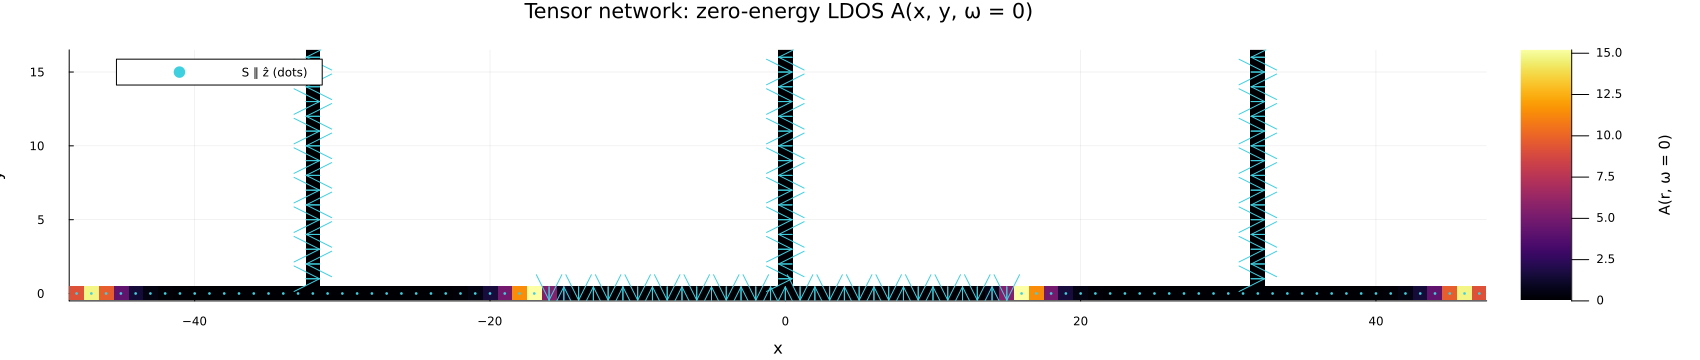

In [8]:
j0 = argmin(abs.(ωs))
xs_ = first.(xy); ys_ = last.(xy)
xg = minimum(xs_):maximum(xs_); yg = minimum(ys_):maximum(ys_)
grid = fill(NaN, length(yg), length(xg))
for (i, (x, y)) in enumerate(xy); grid[y - first(yg) + 1, x - first(xg) + 1] = A_tn[i, j0]; end
Sv = [array_spin(a, f0)(c, s, n) for (c, s, n) in sl]
Sx = getindex.(Sv, 1); Sy = getindex.(Sv, 2)
inpl = hypot.(Sx, Sy) .> 0.5
pl = heatmap(xg, yg, grid; c=:inferno, clims=(0, maximum(A_tn[:, j0])), aspect_ratio=:equal,
             xlims=(first(xg) - 0.5, last(xg) + 0.5), ylims=(first(yg) - 0.5, last(yg) + 0.5),
             xlabel="x", ylabel="y", colorbar_title="A(r, ω = 0)", background_color_inside=:white,
             title="Tensor network: zero-energy LDOS A(x, y, ω = 0)", size=(1700, 360), margin=5Plots.mm)
sc = 1 / 1.1
quiver!(pl, xs_[inpl] .- sc .* Sx[inpl] ./ 2, ys_[inpl] .- sc .* Sy[inpl] ./ 2;
        quiver=(sc .* Sx[inpl], sc .* Sy[inpl]), color="#3FD0E0", lw=1)
scatter!(pl, xs_[.!inpl], ys_[.!inpl]; ms=1.5, color="#3FD0E0", markerstrokewidth=0, label="S ∥ ẑ (dots)")
savefig(pl, joinpath(ROOT, "nb_tn_ldos.png")); pl

## 6. Gates followed by partial fusion with TDVP

Three runs, each one evolution of $\psi_A$ and $\psi_B$ from `ψ0` (section 5): **Z** (exchange_12 twice, then the partial fusion of pair A),
**X** (exchange_23 twice with `rot_Tx = 400`, then the fusion) and **F** (the fusion with no gate). Snapshots every 5 time units during the gate
and every 1 during the fusion. After one and two exchanges the gate is read out from the overlaps with `γ0`; at the end of the fusion the
leakage is measured against the four lowest states of the final $H$ (DMRG), and the adiabatic $\Delta Q$ of pair A is that of the $+E_A$ state.

**Caching and threads.** Each run is saved to `msh_tjunctions_tdvp_{Z,X,F}.jls` (both modes, as numbers) and loaded on later runs; set
`RUN_TDVP = true` to recompute. The six evolutions (3 runs × 2 modes) run as parallel tasks, one per Julia thread, with BLAS on one thread.
A full run takes about 2.5 hours with six threads, dominated by X (T ≈ 8100).

**Progress.** Each evolution appends a line to `tdvp_progress.log` at every 1% of its protocol (time, bond dimension, ΔQ of the mode,
elapsed time and an estimate of the remaining time), and `tdvp_status.txt` always holds the latest line of every evolution. Follow them with
`tail -f tdvp_progress.log` or `cat tdvp_status.txt`.

**Outputs.** δn on the horizontal chain and ΔQ(t) for Z and X are written to `msh_gate_density_tdvp_{Z,X}.csv` and `msh_gate_dQ_tdvp_{Z,X}.csv`.

In [9]:
using Base.Threads: @spawn
# horizontal chain, left to right: per cell, left arm n = 15 … 0 then junction + right arm n = 0 … 15
hsites = [(c, s, n) for c in 1:a.ncell for (s, ns) in ((2, 15:-1:0), (1, 0:15)) for n in ns]
xh = [round(Int, array_pos(a, c, s, n)[1]) for (c, s, n) in hsites]
q = Fusion(); Tf = duration(q)

"Run `kind` (\"Z\", \"X\" or \"F\"): MovingArrayH of gate + fusion, snapshot times, T₁ (one exchange) and T_gate."
function protocol(kind)
    if kind == "Z"
        p = Exchange12(); fg = t -> f_array_braid(a, p, f0, t); T1 = duration(p); mov = [1]
    elseif kind == "X"
        p = Exchange23(rot_T=400.0); fg = t -> f_array_23(p, f0, t); T1 = duration(p); mov = [1, 2]
    else
        fg = t -> f0; T1 = 0.0; mov = [1]
    end
    Tg = 2T1
    B = MovingArrayH(a, t -> t < Tg ? fg(t < T1 ? t : t - T1) : f_fuse(q, f0, t - Tg), f0, mov; sites)
    return (; B, T1, Tg, tsnap = vcat(collect(0.0:5.0:Tg), collect(Tg+1.0:1.0:Tg+Tf)))
end

# ── progress log (appended) and status file (one line per evolution, overwritten) ──
const LOG_FILE, STATUS_FILE = joinpath(ROOT, "tdvp_progress.log"), joinpath(ROOT, "tdvp_status.txt")
const LOG_LOCK, STATUS = ReentrantLock(), Dict{String,String}()
stamp() = Libc.strftime("%Y-%m-%d %H:%M:%S", time())
function tdvp_log(key, msg; append=true)
    lock(LOG_LOCK) do
        append && open(io -> println(io, stamp(), "  ", rpad(key, 4), msg), LOG_FILE, "a")
        STATUS[key] = msg
        open(STATUS_FILE, "w") do io
            println(io, "TDVP status (", stamp(), ")")
            for k in sort(collect(keys(STATUS))); println(io, rpad(k, 4), STATUS[k]); end
        end
    end
end
hms(s) = (s = round(Int, s); @sprintf("%d:%02d:%02d", s ÷ 3600, (s % 3600) ÷ 60, s % 60))

"One mode of one run, with progress logging (every 1% to the log, every snapshot to the status file)."
function run_mode(kind, k, P)
    key = kind * "AB"[k:k]; Tend = P.tsnap[end]; t_start = time(); next = Ref(0.01)
    tdvp_log(key, @sprintf("start: T_gate = %.0f, T_end = %.0f, %d snapshots, thread %d", P.Tg, Tend, length(P.tsnap), Threads.threadid()))
    function logf(i, nt, t, χ, dq)
        f = t / Tend; el = time() - t_start
        msg = @sprintf("t = %7.1f / %.0f (%5.1f%%)  χ = %2d  ΔQ = %+.6f  elapsed %s  remaining ≈ %s",
                       t, Tend, 100f, χ, dq, hms(el), hms(el * (1 - f) / f))
        tdvp_log(key, msg; append = f >= next[] || i == nt)
        f >= next[] && (next[] = floor(100f + 1) / 100)
    end
    r = try
        evolve_mode_tdvp(P.B, ψ0[k], P.tsnap; γ0, slist=hsites, log=logf)
    catch err
        tdvp_log(key, "FAILED: " * sprint(showerror, err)); rethrow()
    end
    secs = time() - t_start
    tdvp_log(key, @sprintf("done in %s, max χ = %d", hms(secs), maximum(r.χ)))
    return merge(r, (; secs))
end

# ── zero modes of the Hamiltonian at the end of the fusion (the same for every run) ──
HT = protocol("F").B(Tf)
t_fin = @elapsed begin
    ψF, _, _ = quiet(() -> zero_mode_subspace(HT, sites; nzero=4))
    EF, φF = ritz(HT, quiet(() -> refine_subspace(HT, ψF; σ=1e-3)))
end
SF = [inner(x, y) for x in φF, y in φF]
fusion_leak(ψ) = (c = [inner(φ, ψ) for φ in φF]; 1 - real(c' * (SF \ c)))
iA = argmax(EF)                                                       # +E_A (pair A is split by the fusion)
ΔQad_A, E_A = ΔQ_mps(φF[iA]), EF[iA]
@printf("final H (DMRG, %.0f s): lowest energies %s;  adiabatic ΔQ of pair A = %+.6f\n", t_fin, string(round.(EF, sigdigits=3)), ΔQad_A)

# ── run (or load) Z, X and F; the six evolutions run in parallel ──
cache(kind) = joinpath(ROOT, "msh_tjunctions_tdvp_$kind.jls")
kinds = ("Z", "X", "F")
P_of = Dict(k => protocol(k) for k in kinds)
todo = [k for k in kinds if RUN_TDVP || !isfile(cache(k))]
isempty(todo) || println("running TDVP for ", join(todo, ", "), " on ", Threads.nthreads(), " threads; progress in ", basename(LOG_FILE),
                         " and ", basename(STATUS_FILE))
nblas = BLAS.get_num_threads(); BLAS.set_num_threads(1)
tasks = Dict((kind, k) => @spawn(run_mode(kind, k, P_of[kind])) for kind in todo for k in 1:2)
for kind in todo
    rs = [fetch(tasks[(kind, k)]) for k in 1:2]
    data = (; ts = rs[1].ts, z = [r.z for r in rs], dQ = [r.dQ for r in rs], dn = [r.dn for r in rs], χ = [r.χ for r in rs],
            leak_fus = [fusion_leak(r.ψT) for r in rs], secs = [r.secs for r in rs], threads = Threads.nthreads())
    serialize(cache(kind), data)
    println("saved ", basename(cache(kind)))
end
BLAS.set_num_threads(nblas)

# ── analysis of each run ──
function analyze(kind)
    P, d = P_of[kind], deserialize(cache(kind))
    @assert d.ts ≈ P.tsnap
    out = Dict{Symbol,Any}(:Tg => P.Tg, :ts => d.ts, :dQ => d.dQ[1] .+ d.dQ[2], :D => d.dn[1] .+ d.dn[2], :χ => max.(d.χ...),
                           :secs => d.secs, :threads => d.threads)
    if P.Tg > 0
        zat(t) = (i = findfirst(≈(t), d.ts); hcat(d.z[1][:, i], d.z[2][:, i]))
        out[:one], out[:two] = gate_summary(zat(P.T1)), gate_summary(zat(P.Tg))
    end
    fus = d.ts .>= P.Tg
    out[:fusion] = (; ΔQ = out[:dQ][end], ΔQpair = [d.dQ[1][end], d.dQ[2][end]], leak = d.leak_fus,
                     ts = d.ts[fus] .- P.Tg, ΔQt = out[:dQ][fus])
    return out
end
rZ, rX, rF = analyze("Z"), analyze("X"), analyze("F")

function write_density(name, r)
    csv = joinpath(ROOT, "msh_gate_density_tdvp_$name.csv")
    open(csv, "w") do io
        println(io, "t,x,dn")
        for (i, t) in enumerate(r[:ts]), (j, x) in enumerate(xh)
            println(io, t, ",", x, ",", r[:D][i, j])
        end
    end
    csv2 = joinpath(ROOT, "msh_gate_dQ_tdvp_$name.csv")
    open(csv2, "w") do io
        println(io, "t,dQ")
        for (t, v) in zip(r[:ts], r[:dQ]); println(io, t, ",", v); end
    end
    println("wrote ", basename(csv), ", ", basename(csv2))
end

function density_figure(ts, D, Tg, gate; method="MPS/TDVP")
    L = log10.(max.(abs.(D), 1e-16))
    p1 = heatmap(xh, ts, L; c=:inferno, clims=(-12, 0), xlabel="x (horizontal chain)", ylabel="t",
                 colorbar_title="log₁₀|n₁ − n₀|", title="$method: log₁₀|δn(x, t)|, full $gate protocol + fusion")
    hline!(p1, [Tg / 2, Tg]; color=:white, ls=:dash, lw=1, label="")
    vline!(p1, [-32, 0, 32]; color=:gray, ls=:dot, lw=0.8, label="")
    sel = ts .>= Tg; lim = maximum(abs, D[sel, :])
    p2 = heatmap(ts[sel] .- Tg, xh, permutedims(D[sel, :]); c=:RdBu, clims=(-lim, lim),
                 xlabel="t − T_gate (fusion)", ylabel="x (horizontal chain)", colorbar_title="δn = n₁ − n₀",
                 title=@sprintf("%s: δn(x, t) during the fusion after %s  (Σ_chain δn = %+.3f)", method, gate, sum(D[end, :])))
    hline!(p2, [-32, 0, 32]; color=:gray, ls=:dot, lw=0.8, label="")
    return plot(p1, p2; layout=(1, 2), size=(1700, 560), margin=6Plots.mm, titlefontsize=10)
end

final H (DMRG, 251 s): lowest energies [-0.0439, -1.16e-9, 1.16e-9, 0.0439];  adiabatic ΔQ of pair A = -0.476854
running TDVP for Z, X, F on 6 threads; progress in tdvp_progress.log and tdvp_status.txt
saved msh_tjunctions_tdvp_Z.jls
saved msh_tjunctions_tdvp_X.jls
saved msh_tjunctions_tdvp_F.jls


density_figure (generic function with 1 method)

### Z gate: exchange_12 twice on junction 1, then partial fusion (and fusion with no gate)

Z: exchange_12 once: phase 90.7180°, leak [9.72e-7, 1.65e-11];  twice: phase 181.4359°, leak [1.99e-6, 2.07e-11], P(0→1) = 1.9e-18
Z + fusion   ΔQ = -0.477717 (A -0.477717, B +1.4e-07), adiabatic (pair A) -0.476854, E_A = 0.0439, leak [3.69e-5, 1.44e-11]
fusion only  ΔQ = -0.477372 (A -0.477373, B +9.7e-08), adiabatic (pair A) -0.476854, E_A = 0.0439, leak [3.78e-5, 7.03e-12]
wrote msh_gate_density_tdvp_Z.csv, msh_gate_dQ_tdvp_Z.csv


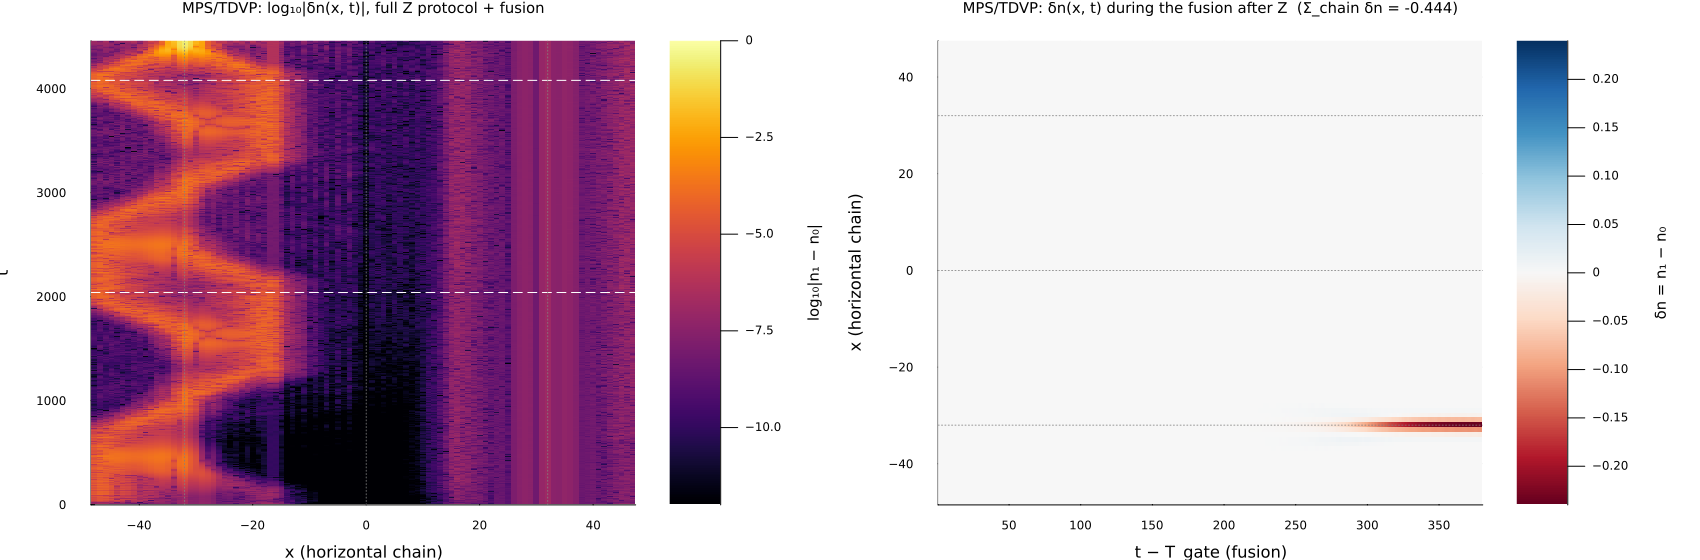

In [10]:
@printf("Z: exchange_12 once: phase %.4f°, leak %s;  twice: phase %.4f°, leak %s, P(0→1) = %.1e\n",
        rZ[:one].phase, string(round.(rZ[:one].leak, sigdigits=3)), rZ[:two].phase, string(round.(rZ[:two].leak, sigdigits=3)), rZ[:two].P01)
for (lbl, r) in (("Z + fusion", rZ), ("fusion only", rF))
    f = r[:fusion]
    @printf("%-12s ΔQ = %+.6f (A %+.6f, B %+.1e), adiabatic (pair A) %+.6f, E_A = %.4f, leak %s\n",
            lbl, f.ΔQ, f.ΔQpair..., ΔQad_A, E_A, string(round.(f.leak, sigdigits=3)))
end
write_density("Z", rZ)
pz = density_figure(rZ[:ts], rZ[:D], rZ[:Tg], "Z"); savefig(pz, joinpath(ROOT, "nb_tdvp_density_Z.png")); pz

### X gate: exchange_23 twice through junction 2 (rot_Tx = 400), then partial fusion

X (rot_Tx = 400): leak [3.42e-5, 3.49e-5], θ = 174.939° about n̂ = [-1.0, 0.0, -0.0], P(0→1) = 0.998051; fusion ΔQ = +0.477004 (A +0.476113, B +8.9e-04), leak [8.08e-5, 3.33e-5]
wrote msh_gate_density_tdvp_X.csv, msh_gate_dQ_tdvp_X.csv


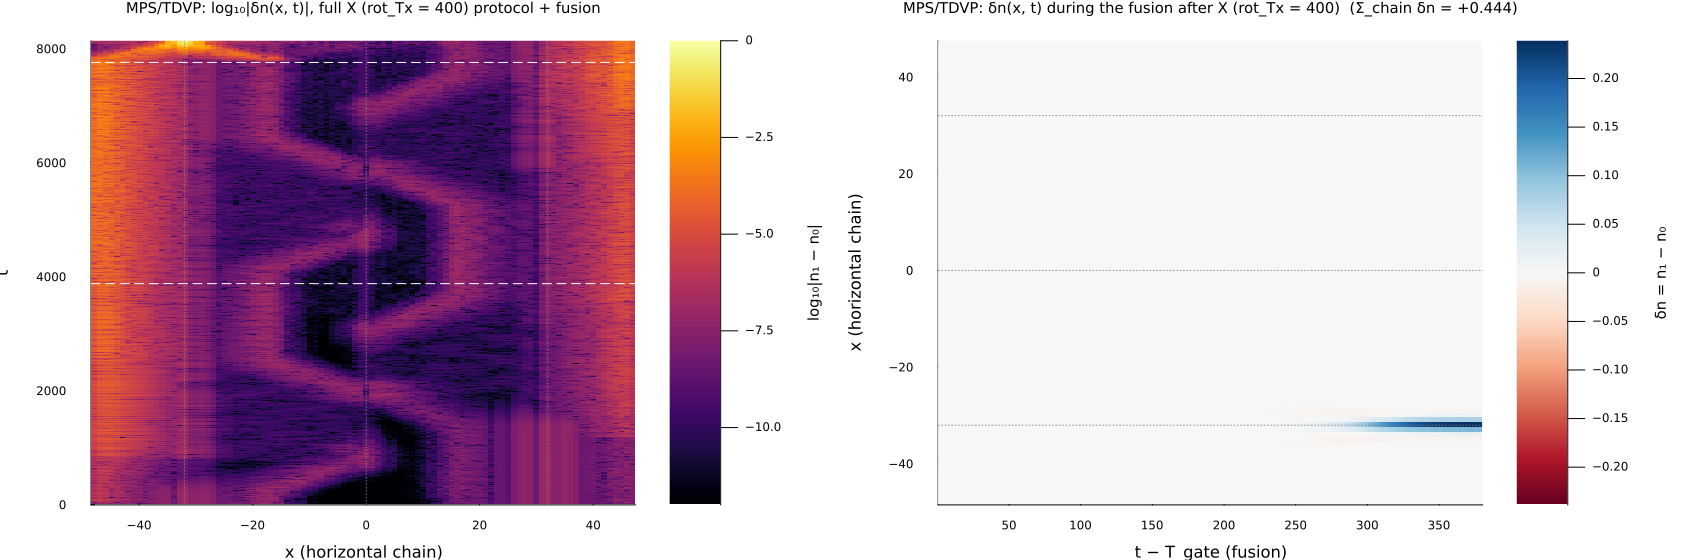

In [11]:
r, f = rX[:two], rX[:fusion]
@printf("X (rot_Tx = 400): leak %s, θ = %.3f° about n̂ = %s, P(0→1) = %.6f; fusion ΔQ = %+.6f (A %+.6f, B %+.1e), leak %s\n",
        string(round.(r.leak, sigdigits=3)), rad2deg(r.L.θ), string(round.(r.L.n̂, digits=4)), r.P01, f.ΔQ, f.ΔQpair...,
        string(round.(f.leak, sigdigits=3)))
write_density("X", rX)
px = density_figure(rX[:ts], rX[:D], rX[:Tg], "X (rot_Tx = 400)"); savefig(px, joinpath(ROOT, "nb_tdvp_density_X.png")); px

## 7. ΔQ during the fusion and the bond dimension

Left: $\Delta Q(t)$ during the partial fusion for the three runs. Right: the largest bond dimension of $\psi_A$, $\psi_B$ over each protocol
(`maxdim = 64`; the dashed line marks the start of the fusion).

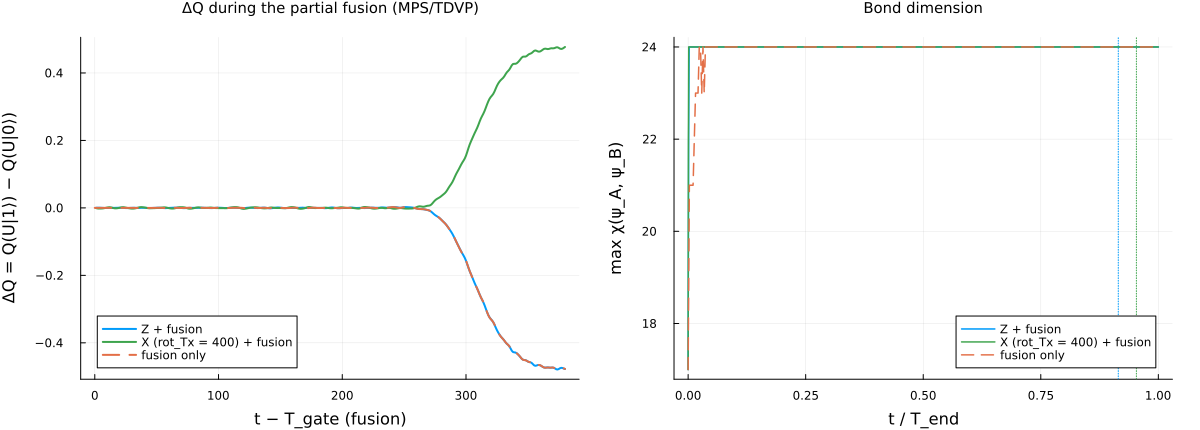

In [12]:
pq1 = plot(xlabel="t − T_gate (fusion)", ylabel="ΔQ = Q(U|1⟩) − Q(U|0⟩)", legend=:bottomleft,
           title="ΔQ during the partial fusion (MPS/TDVP)", titlefontsize=10)
pq2 = plot(xlabel="t / T_end", ylabel="max χ(ψ_A, ψ_B)", legend=:bottomright, title="Bond dimension", titlefontsize=10)
for (lbl, r, ls, col) in (("Z + fusion", rZ, :solid, 1), ("X (rot_Tx = 400) + fusion", rX, :solid, 3), ("fusion only", rF, :dash, 2))
    plot!(pq1, r[:fusion].ts, r[:fusion].ΔQt; lw=2, ls, color=col, label=lbl)
    plot!(pq2, r[:ts] ./ r[:ts][end], r[:χ]; lw=1.5, ls, color=col, label=lbl)
    r[:Tg] > 0 && vline!(pq2, [r[:Tg] / r[:ts][end]]; color=col, ls=:dot, label="")
end
pq = plot(pq1, pq2; layout=(1, 2), size=(1200, 430), margin=5Plots.mm)
savefig(pq, joinpath(ROOT, "nb_tdvp_dQ.png")); pq

## 8. Summary of the results

The tensor-network results, also written to `msh_tjunctions_tn_gates.csv` (one `key,value` row each). `tjunctions_compare.ipynb` compares
them with the exact-diagonalization results of `tjunctions_python_ed.ipynb`.

In [13]:
summary = [
    ("S_phase",      "exchange_12 once: relative phase (°)",       rZ[:one].phase),
    ("Z_phase",      "Z: relative phase (°)",                      rZ[:two].phase),
    ("Z_leak_A",     "Z: leak ψ_A",                                rZ[:two].leak[1]),
    ("Z_leak_B",     "Z: leak ψ_B",                                rZ[:two].leak[2]),
    ("X_theta",      "X: rotation angle θ (°)",                    rad2deg(rX[:two].L.θ)),
    ("X_P01",        "X: P(0→1)",                                  rX[:two].P01),
    ("X_leak_A",     "X: leak ψ_A",                                rX[:two].leak[1]),
    ("X_leak_B",     "X: leak ψ_B",                                rX[:two].leak[2]),
    ("Z_fus_dQ",     "fusion ΔQ after Z",                          rZ[:fusion].ΔQ),
    ("X_fus_dQ",     "fusion ΔQ after X",                          rX[:fusion].ΔQ),
    ("F_fus_dQ",     "fusion ΔQ, no gate",                         rF[:fusion].ΔQ),
    ("Z_fus_leak_A", "fusion leak ψ_A after Z",                    rZ[:fusion].leak[1]),
    ("X_fus_leak_A", "fusion leak ψ_A after X",                    rX[:fusion].leak[1]),
    ("F_fus_leak_A", "fusion leak ψ_A, no gate",                   rF[:fusion].leak[1]),
    ("fus_dQad_A",   "adiabatic ΔQ of pair A at the end of fusion", ΔQad_A),
    ("fus_E_A",      "E_A at the end of the fusion",               E_A)]
for (_, lbl, v) in summary; @printf("%-46s %+.6g\n", lbl, v); end
gates_csv = joinpath(ROOT, "msh_tjunctions_tn_gates.csv")
open(gates_csv, "w") do io
    println(io, "key,value")
    for (k, _, v) in summary; println(io, k, ",", v); end
end
println("wrote ", basename(gates_csv))

exchange_12 once: relative phase (°)           +90.718
Z: relative phase (°)                          +181.436
Z: leak ψ_A                                    +1.99193e-06
Z: leak ψ_B                                    +2.07467e-11
X: rotation angle θ (°)                        +174.939
X: P(0→1)                                      +0.998051
X: leak ψ_A                                    +3.41817e-05
X: leak ψ_B                                    +3.48854e-05
fusion ΔQ after Z                              -0.477717
fusion ΔQ after X                              +0.477004
fusion ΔQ, no gate                             -0.477372
fusion leak ψ_A after Z                        +3.6929e-05
fusion leak ψ_A after X                        +8.07556e-05
fusion leak ψ_A, no gate                       +3.77714e-05
adiabatic ΔQ of pair A at the end of fusion    -0.476854
E_A at the end of the fusion                   +0.0438539
wrote msh_tjunctions_tn_gates.csv


## 9. Cost of the tensor-network route

**Measured times.** Wall time of the DMRG steps (section 5 and the final Hamiltonian of section 6) and of each TDVP evolution, with the number of
time steps and the time per step. Every evolution ran on one thread (BLAS on one thread), like the dense evolutions of
`tjunctions_python_ed.ipynb`, so the two are directly comparable in `tjunctions_compare.ipynb`.

**Scaling.** The array above has $2^L = 16$ sites per arm (144 sites). One TDVP step is timed for $L = 4, 5, 6$ (144, 288, 576 sites) with the
initial Hamiltonian and a random MPS of bond dimension 24 (the bond dimension reached in section 6), and the memory of an MPS (number of complex
entries) is compared with that of a dense vector ($4 \times$ number of sites). The times and sizes are written to `msh_tjunctions_tn_timing.csv`.

In [14]:
timing = [("dmrg_ldos", t_dmrg), ("dmrg_mzm", t_loc), ("dmrg_final", t_fin)]
@printf("%-34s %10s %8s %12s\n", "", "wall time", "steps", "per step")
for (lbl, v) in (("DMRG, six subgap states (section 5)", t_dmrg), ("refinement + localization (section 5)", t_loc),
                 ("DMRG, final Hamiltonian (section 6)", t_fin))
    @printf("%-34s %10s\n", lbl, hms(v))
end
for (kind, r) in (("Z", rZ), ("X", rX), ("F", rF)), k in 1:2
    nsteps = round(Int, r[:ts][end] / 0.1)
    @printf("TDVP %s, mode %s (%d threads) %14s %8d %10.1f ms\n", kind, "AB"[k], r[:threads], hms(r[:secs][k]), nsteps, 1e3 * r[:secs][k] / nsteps)
    push!(timing, ("tdvp_$(kind)_$("AB"[k])", r[:secs][k]), ("steps_$(kind)", nsteps))
end

"Time per TDVP step (dt = 0.1, maxdim = 64) for arms of 2^L sites, initial Hamiltonian, random MPS of bond dimension χ."
function bench_tdvp(L; χ=24, nsteps=10)
    aL = TArray(L=L, ncell=3)
    B = MovingArrayH(aL, t -> f0, f0, [1])
    ψ = random_mps(ComplexF64, B.sites; linkdims=χ); ψ /= norm(ψ)
    step(n) = TB.evolve_with_tdvp_timedep(t -> B(t), ψ, n, 0.1; maxdim=64, cutoff=1e-20, tol=1e-12, krylovdim=30, reverse_step=true)
    step(1)                                                                            # compile
    t = @elapsed step(nsteps)
    nsite = 3 * 2^L * aL.ncell
    return (; L, nsite, per_step = t / nsteps, mps_size = sum(dim, ψ), dense_size = 4nsite)
end
nblas = BLAS.get_num_threads(); BLAS.set_num_threads(1)
bench = [bench_tdvp(L) for L in 4:6]
BLAS.set_num_threads(nblas)
println()
@printf("%6s %8s %14s %16s %16s\n", "L", "sites", "TDVP step", "MPS entries", "dense entries")
for b in bench
    @printf("%6d %8d %11.1f ms %16d %16d\n", b.L, b.nsite, 1e3 * b.per_step, b.mps_size, b.dense_size)
    push!(timing, ("bench_sites_L$(b.L)", b.nsite), ("bench_step_L$(b.L)", b.per_step), ("bench_mps_size_L$(b.L)", b.mps_size))
end
timing_csv = joinpath(ROOT, "msh_tjunctions_tn_timing.csv")
open(timing_csv, "w") do io
    println(io, "key,value")
    for (k, v) in timing; println(io, k, ",", v); end
end
println("wrote ", basename(timing_csv))

                                    wall time    steps     per step
DMRG, six subgap states (section 5)    0:00:50
refinement + localization (section 5)    0:04:08
DMRG, final Hamiltonian (section 6)    0:04:11
TDVP Z, mode A (6 threads)        1:17:48    44600      104.7 ms
TDVP Z, mode B (6 threads)        1:06:57    44600       90.1 ms
TDVP X, mode A (6 threads)        2:18:53    81400      102.4 ms
TDVP X, mode B (6 threads)        2:16:30    81400      100.6 ms
TDVP F, mode A (6 threads)        0:08:06     3800      127.9 ms
TDVP F, mode B (6 threads)        0:06:32     3800      103.3 ms

     L    sites      TDVP step      MPS entries    dense entries
     4      144        87.5 ms             4845              576
     5      288       126.3 ms             5997             1152
     6      576       258.5 ms             7149             2304
wrote msh_tjunctions_tn_timing.csv
